# LiDAR DBH & Volume Parameter Grid Search

This notebook performs a systematic, parallelized grid search across:
1. **DBH Estimation Methods** (`ensemble`, `single_ransac`, `ls`) and their parameter grids.
2. **Volume Reconstruction Methods** (`cylinder`, `voxel`, `axis_profile`, `frustum`, `taper`) and their parameter grids.

It compares the LiDAR-derived metrics with the real field inventory measurements (ground truth) from your datasets and identifies the optimal parameter combinations for both diameter and volume estimation.

Since there are thousands of runs, it executes in parallel using a process pool and displays progress dynamically.


In [26]:
import os, sys
if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir(os.path.abspath(os.path.join(os.getcwd(), "../..")))
if os.getcwd() not in sys.path:
    sys.path.insert(0, os.getcwd())

import os
import sys
import numpy as np
import pandas as pd
from pathlib import Path
from itertools import product
from concurrent.futures import ProcessPoolExecutor, as_completed
import matplotlib.pyplot as plt
import seaborn as sns

# Add project root to path for imports
PROJECT_ROOT = Path(os.getcwd()).resolve()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from eucalipto.io import load_cloud_auto
from eucalipto.dbh_methods import estimate_dbh
from eucalipto.volume_methods import estimate_volume

# Progress bar imports
try:
    from tqdm.notebook import tqdm
except ImportError:
    # Text-based fallback in case tqdm is not available
    def tqdm(iterable, total=None, desc="Progress"):
        total_len = total or len(iterable)
        print(f"Starting {desc}: {total_len} tasks...")
        for idx, item in enumerate(iterable):
            yield item
            if (idx + 1) % max(1, total_len // 10) == 0:
                print(f"  -> {desc}: {int((idx + 1) / total_len * 100)}% completed ({idx + 1}/{total_len})")

# Plot styling
sns.set_theme(style="darkgrid")
plt.rcParams["figure.figsize"] = (12, 6)


## 1. Grid Search Configuration

Set up the paths to your spreadsheet ground truths and the classified/segmented point cloud. 
We will select a specific plot (e.g., plot `500` in Talhão `062-063`) to compare with the corresponding segmented point cloud.

In [27]:
# Paths to field spreadsheets and segmented cloud
RESULT_IFPC_PATH = "/mnt/scratch/matheuspimenta/euc/canoa/IFPC-Canoas/Result_IFPC_Canoas.xlsx"
CUBAGEM_PATH = "/mnt/scratch/matheuspimenta/euc/canoa/IFPC-Canoas/Cubagem_Canoas.xls"
CLASSIFIED_CLOUD_PATH = "results/canoa/parcelas_t63/ff3d_full/classified_cloud.laz"

# Ground truth plot selection
TALHAO_GT = "062-063"
PARCELA_GT = 500

# Number of parallel workers for the grid search
NUM_WORKERS = 8


## 2. Load Field Ground Truths

We load the individual tree metrics from the `Covas` sheet, filtering for the selected plot and removing trees with missing volumes or DBHs.

In [28]:
print("Loading ground truths from Excel...")
df_covas = pd.read_excel(RESULT_IFPC_PATH, sheet_name="Covas")
df_gt = df_covas[
    (df_covas["Talhão"] == TALHAO_GT) & 
    (df_covas["PAR_CODIGO"] == PARCELA_GT) & 
    (df_covas["VTCC Volume (m³)"].notnull()) & 
    (df_covas["Dap (cm)"].notnull())
].copy()

# Ground truth statistics
gt_count = len(df_gt)
gt_mean_dbh = df_gt["Dap (cm)"].mean()
gt_mean_height = df_gt["Alt.obs (m)"].replace(0, np.nan).fillna(df_gt["Altura (m)"]).mean()
gt_total_volume = df_gt["VTCC Volume (m³)"].sum()

print(f"\nGround Truth (Plot {PARCELA_GT}) Summary:")
print(f"  Total Valid Trees: {gt_count}")
print(f"  Mean DBH: {gt_mean_dbh:.2f} cm")
print(f"  Mean Height: {gt_mean_height:.2f} m")
print(f"  Total Volume: {gt_total_volume:.4f} m³")


Loading ground truths from Excel...

Ground Truth (Plot 500) Summary:
  Total Valid Trees: 40
  Mean DBH: 15.22 cm
  Mean Height: 25.90 m
  Total Volume: 8.7327 m³


## 3. Load and Process LiDAR Point Cloud

We load the classified point cloud, identify the segment ID and trunk classification columns, and pre-extract each valid tree's point cloud, bounding-box height, and trunk mask.

In [29]:
print(f"Loading LiDAR point cloud: {CLASSIFIED_CLOUD_PATH} ...")
pts, extras, _ = load_cloud_auto(CLASSIFIED_CLOUD_PATH)

# Detect tree segment column
tree_id_col = None
for col in ['tree_id', 'tree_id_label', 'tree_label', 'segment_id']:
    if col in extras:
        tree_id_col = col
        break

# Detect trunk classification column
trunk_col = None
for col in ['trunk_leaf_label', 'semantic_seg', 'semantic_pred', 'leafwood_pred']:
    if col in extras:
        trunk_col = col
        break

if not tree_id_col:
    raise ValueError("No tree segment column found in point cloud!")

tree_ids = extras[tree_id_col].astype(int)
unique_tree_ids = sorted([int(tid) for tid in np.unique(tree_ids) if tid >= 0])
trunk_labels = extras[trunk_col].astype(int) if trunk_col else np.ones(len(pts), dtype=int)

print(f"\nLiDAR Point Cloud Statistics:")
print(f"  Total points: {pts.shape[0]}")
print(f"  Segmented Trees Found: {len(unique_tree_ids)}")

# Prepare tree dictionaries for parallel worker process memory mapping
points_dict = {}
heights_dict = {}
trunk_masks_dict = {}

for tid in unique_tree_ids:
    mask = tree_ids == tid
    t_pts = pts[mask]
    
    # Calculate height from z bounding box
    z_min, z_max = t_pts[:, 2].min(), t_pts[:, 2].max()
    heights_dict[tid] = float(z_max - z_min)
    
    # Center tree points for WebGL stability and numerical accuracy
    ctr_x = np.median(t_pts[:, 0])
    ctr_y = np.median(t_pts[:, 1])
    base_z = z_min
    
    pts_centered = t_pts.copy()
    pts_centered[:, 0] -= ctr_x
    pts_centered[:, 1] -= ctr_y
    pts_centered[:, 2] -= base_z
    points_dict[tid] = pts_centered
    
    # Extract trunk-only points for DBH
    t_trunk_labels = trunk_labels[mask]
    trunk_mask = t_trunk_labels == 1
    trunk_masks_dict[tid] = trunk_mask

print(f"Precomputed heights and trunk masks for {len(points_dict)} trees.")


Loading LiDAR point cloud: results/canoa/parcelas_t63/ff3d_full/classified_cloud.laz ...

LiDAR Point Cloud Statistics:
  Total points: 1264190
  Segmented Trees Found: 51
Precomputed heights and trunk masks for 51 trees.


## 4. Parameter Grid Definitions

We define parameter search grids for both DBH estimation and volume reconstruction methods.
*   **DBH parameter sets**: Grid cover multi-slice `ensemble`, `single_ransac`, and standard `ls`.
*   **Volume parameter sets**: Voxel `voxel_size` grid, and slice grids for `axis_profile`, `frustum`, and `taper`.

We optimize the search:
1.  **Cylinder volume tasks**: Cylinder relies directly on DBH. We run it for all DBH parameter configurations.
2.  **Other volume tasks**: Other methods do not use DBH. We run them with a default robust DBH setup (so we can still record tree DBH values) and search over their respective volume parameters.
This keeps the run time highly optimized while searching the entire parameter space.


In [30]:
# DBH parameter combinations
dbh_grids = {
    "ensemble": [
        {"offset_range": org, "n_slices": ns, "slice_thickness": st, "ransac_thresh": rt}
        for org in [0.2, 0.4]
        for ns in [5, 8]
        for st in [0.10, 0.20]
        for rt in [0.01, 0.03]
    ],
    "single_ransac": [
        {"slice_thickness": st, "ransac_thresh": rt}
        for st in [0.10, 0.20]
        for rt in [0.01, 0.03]
    ],
    "ls": [
        {"slice_thickness": st}
        for st in [0.10, 0.20]
    ]
}

# Volume parameter combinations
volume_grids = {
    "cylinder": [{}],
    "voxel": [
        {"voxel_size": vs}
        for vs in [0.02, 0.05, 0.08, 0.10]
    ],
    "axis_profile": [
        {"n_slices": ns, "slice_thickness": st, "radius_percentile": rp, "min_points_per_slice": 20}
        for ns in [10, 20, 30]
        for st in [0.15, 0.30, 0.50]
        for rp in [80.0, 85.0, 90.0]
    ],
    "frustum": [
        {"n_height_samples": nh, "slice_thickness": st, "ransac_thresh": rt, "min_inliers": 3}
        for nh in [10, 15, 20]
        for st in [0.15, 0.20, 0.30]
        for rt in [0.02, 0.03, 0.04]
    ],
    "taper": [
        {"n_height_samples": nh, "slice_thickness": st, "ransac_thresh": rt, "min_inliers": 3}
        for nh in [10, 15, 20]
        for st in [0.15, 0.20, 0.30]
        for rt in [0.02, 0.03, 0.04]
    ]
}

# Default DBH configuration to run alongside independent volume estimators
default_dbh_method = "ensemble"
default_dbh_params = {"offset_range": 0.3, "n_slices": 7, "slice_thickness": 0.16, "ransac_thresh": 0.02}
default_dbh_tuple = tuple(sorted(default_dbh_params.items()))

# Compile tasks list
tasks = []

# 1. Cylinder volume tasks: Combine each DBH parameter set with cylinder volume
for dbh_method, grids in dbh_grids.items():
    for grid in grids:
        grid_tuple = tuple(sorted(grid.items()))
        for tid in unique_tree_ids:
            tasks.append((tid, dbh_method, grid_tuple, "cylinder", ()))

# 2. Other volume tasks: Combine default DBH setup with each other volume method config
for vol_method, grids in volume_grids.items():
    if vol_method == "cylinder":
        continue
    for grid in grids:
        grid_tuple = tuple(sorted(grid.items()))
        for tid in unique_tree_ids:
            tasks.append((tid, default_dbh_method, default_dbh_tuple, vol_method, grid_tuple))

print(f"Total parallel tasks generated: {len(tasks)}")


Total parallel tasks generated: 5457


## 5. Parallel Grid Search Engine

We execute the experiments in parallel using Python's `ProcessPoolExecutor` and monitor the progress in real-time with `tqdm` progress bars.

In [31]:
# Global variables in workers to cache point clouds
def init_worker(points, heights, trunk_masks):
    global _points_dict, _heights_dict, _trunk_masks_dict
    _points_dict = points
    _heights_dict = heights
    _trunk_masks_dict = trunk_masks

def run_task(task_args):
    tree_id, dbh_method, dbh_params_tuple, volume_method, volume_params_tuple = task_args
    dbh_params = dict(dbh_params_tuple)
    volume_params = dict(volume_params_tuple)
    
    pts = _points_dict[tree_id]
    h = _heights_dict[tree_id]
    trunk_mask = _trunk_masks_dict[tree_id]
    
    # 1. Estimate DBH
    try:
        trunk_pts = pts[trunk_mask] if np.any(trunk_mask) else pts
        dbh_cm, _ = estimate_dbh(trunk_pts, method=dbh_method, **dbh_params)
    except Exception:
        dbh_cm = float("nan")
        
    # 2. Estimate Volume
    try:
        if volume_method == "cylinder":
            if np.isnan(dbh_cm):
                raise ValueError("Computed DBH is NaN for cylinder volume")
            res = estimate_volume(pts, dbh_cm=dbh_cm, height_m=h, method="cylinder")
        else:
            res = estimate_volume(pts, method=volume_method, **volume_params)
            
        return {
            "tree_id": tree_id,
            "dbh_method": dbh_method,
            "dbh_params_str": str(dbh_params),
            "volume_method": volume_method,
            "volume_params_str": str(volume_params),
            "dbh_cm": dbh_cm,
            "volume_m3": res["volume_m3"],
            "height_m": res["height_m"] or h,
            "status": "success"
        }
    except Exception as e:
        return {
            "tree_id": tree_id,
            "dbh_method": dbh_method,
            "dbh_params_str": str(dbh_params),
            "volume_method": volume_method,
            "volume_params_str": str(volume_params),
            "dbh_cm": dbh_cm,
            "volume_m3": float("nan"),
            "height_m": h,
            "status": "failed"
        }

print(f"Launching parallel grid search using {NUM_WORKERS} workers...")

results = []
with ProcessPoolExecutor(max_workers=NUM_WORKERS, initializer=init_worker, initargs=(points_dict, heights_dict, trunk_masks_dict)) as executor:
    futures = [executor.submit(run_task, task) for task in tasks]
    for fut in tqdm(as_completed(futures), total=len(futures), desc="Grid Search Progress"):
        results.append(fut.result())

print(f"Finished processing all {len(results)} tasks.")


Launching parallel grid search using 8 workers...


/home/matheuspimenta/.conda/envs/euc/lib/python3.12/site-packages/pyransac3d/circle.py:60: RuntimeWarning: invalid value encountered in divide
  vecB_norm = vecB / np.linalg.norm(vecB)
/home/matheuspimenta/.conda/envs/euc/lib/python3.12/site-packages/pyransac3d/circle.py:60: RuntimeWarning: invalid value encountered in divide
  vecB_norm = vecB / np.linalg.norm(vecB)
/home/matheuspimenta/.conda/envs/euc/lib/python3.12/site-packages/pyransac3d/circle.py:64: RuntimeWarning: invalid value encountered in divide
  vecC = vecC / np.linalg.norm(vecC)
/home/matheuspimenta/.conda/envs/euc/lib/python3.12/site-packages/pyransac3d/circle.py:60: RuntimeWarning: invalid value encountered in divide
  vecB_norm = vecB / np.linalg.norm(vecB)
/home/matheuspimenta/.conda/envs/euc/lib/python3.12/site-packages/pyransac3d/circle.py:58: RuntimeWarning: invalid value encountered in divide
  vecA_norm = vecA / np.linalg.norm(vecA)
/home/matheuspimenta/.conda/envs/euc/lib/python3.12/site-packages/pyransac3d/cir

Grid Search Progress:   0%|          | 0/5457 [00:00<?, ?it/s]

/home/matheuspimenta/.conda/envs/euc/lib/python3.12/site-packages/pyransac3d/circle.py:64: RuntimeWarning: invalid value encountered in divide
  vecC = vecC / np.linalg.norm(vecC)
/home/matheuspimenta/.conda/envs/euc/lib/python3.12/site-packages/pyransac3d/circle.py:58: RuntimeWarning: invalid value encountered in divide
  vecA_norm = vecA / np.linalg.norm(vecA)
/home/matheuspimenta/.conda/envs/euc/lib/python3.12/site-packages/pyransac3d/circle.py:80: RuntimeWarning: divide by zero encountered in scalar divide
  mb = (P_rot[2, 1] - P_rot[1, 1]) / (P_rot[2, 0] - P_rot[1, 0])
/home/matheuspimenta/.conda/envs/euc/lib/python3.12/site-packages/pyransac3d/circle.py:87: RuntimeWarning: invalid value encountered in scalar divide
  p_center_x = (
/home/matheuspimenta/.conda/envs/euc/lib/python3.12/site-packages/pyransac3d/circle.py:79: RuntimeWarning: divide by zero encountered in scalar divide
  ma = (P_rot[1, 1] - P_rot[0, 1]) / (P_rot[1, 0] - P_rot[0, 0])
/home/matheuspimenta/.conda/envs/euc

Finished processing all 5457 tasks.


## 6. Evaluate DBH Configurations

We group the experimental results of cylinder runs (where DBH was varied) by DBH method and parameter set, and compare them with the sorted field ground truth DBH values to find the best configuration.

In [32]:
df_res = pd.DataFrame(results)
print("Execution Status Summary:")
print(df_res["status"].value_counts())

# Ground truth values sorted for rank-based matching
gt_volumes_sorted = np.sort(df_gt["VTCC Volume (m³)"].values)
gt_dbhs_sorted = np.sort(df_gt["Dap (cm)"].values)

# Group results by DBH configuration to find best DBH estimator
print("Evaluating DBH estimation configurations...")
df_dbh_eval = df_res[df_res["volume_method"] == "cylinder"].groupby(["dbh_method", "dbh_params_str"])
dbh_summary_rows = []

for (dbh_method, dbh_params_str), group in df_dbh_eval:
    valid_group = group[group["dbh_cm"].notnull() & ~group["dbh_cm"].isna()]
    if len(valid_group) == 0:
        continue
    
    # Matched DBH stats
    est_dbhs_sorted = np.sort(valid_group["dbh_cm"].values)
    num_matched = min(len(gt_dbhs_sorted), len(est_dbhs_sorted))
    if num_matched >= 5:
        matched_gt_dbh = gt_dbhs_sorted[:num_matched]
        matched_est_dbh = est_dbhs_sorted[:num_matched]
        errors = matched_est_dbh - matched_gt_dbh
        rmse = np.sqrt(np.mean(errors ** 2))
        bias = np.mean(errors)
        correlation = np.corrcoef(matched_gt_dbh, matched_est_dbh)[0, 1] if len(matched_gt_dbh) > 1 else float("nan")
    else:
        rmse = float("nan")
        bias = float("nan")
        correlation = float("nan")
        
    dbh_summary_rows.append({
        "dbh_method": dbh_method,
        "dbh_params": dbh_params_str,
        "valid_trees": len(valid_group),
        "mean_dbh_cm": valid_group["dbh_cm"].mean(),
        "rmse_cm": rmse,
        "bias_cm": bias,
        "correlation": correlation
    })

df_dbh_summary = pd.DataFrame(dbh_summary_rows)
df_dbh_summary.sort_values("rmse_cm", inplace=True)
print("\nTop 5 DBH Configurations (Sorted by individual tree RMSE):")
display(df_dbh_summary.head(5))


Execution Status Summary:
status
success    4670
failed      787
Name: count, dtype: int64
Evaluating DBH estimation configurations...

Top 5 DBH Configurations (Sorted by individual tree RMSE):


,dbh_method,dbh_params,valid_trees,mean_dbh_cm,rmse_cm,bias_cm,correlation
11,ensemble,"{'n_slices': 8, 'offset_range': 0.2, 'ransac_t...",43,44.901026,30.450725,26.264702,0.896891
13,ensemble,"{'n_slices': 8, 'offset_range': 0.4, 'ransac_t...",42,46.918143,34.712534,28.315110,0.896173
15,ensemble,"{'n_slices': 8, 'offset_range': 0.4, 'ransac_t...",41,50.145080,37.139654,31.388054,0.913265
9,ensemble,"{'n_slices': 8, 'offset_range': 0.2, 'ransac_t...",41,51.831028,40.450296,33.521097,0.914363
5,ensemble,"{'n_slices': 5, 'offset_range': 0.4, 'ransac_t...",41,50.419960,40.457302,31.665523,0.860615


## 7. Evaluate Volume Configurations

We evaluate all volume configurations based on plot-level relative errors and matched individual tree RMSEs.

In [33]:
# Group by DBH and Volume configurations to evaluate volume estimation
print("Evaluating Volume estimation configurations...")
df_vol_eval = df_res.groupby(["dbh_method", "dbh_params_str", "volume_method", "volume_params_str"])
vol_summary_rows = []

for (dbh_method, dbh_params_str, vol_method, vol_params_str), group in df_vol_eval:
    valid_group = group[group["volume_m3"].notnull() & ~group["volume_m3"].isna()]
    if len(valid_group) == 0:
        continue
        
    # Aggregate plot volume
    est_total_vol = valid_group["volume_m3"].sum()
    est_mean_height = valid_group["height_m"].mean()
    
    # Pre-calculated DBHs
    valid_dbhs = valid_group["dbh_cm"].dropna()
    est_mean_dbh = valid_dbhs.mean() if len(valid_dbhs) > 0 else float("nan")
    
    plot_vol_bias = est_total_vol - gt_total_volume
    plot_vol_rel_err_pct = (plot_vol_bias / gt_total_volume) * 100.0
    
    # Sort LiDAR estimations for rank-based matching
    group_sorted = valid_group.sort_values("height_m")
    est_volumes_sorted = group_sorted["volume_m3"].values
    
    num_matched = min(len(gt_volumes_sorted), len(est_volumes_sorted))
    if num_matched >= 5:
        matched_gt = gt_volumes_sorted[:num_matched]
        matched_est = est_volumes_sorted[:num_matched]
        errors = matched_est - matched_gt
        rmse = np.sqrt(np.mean(errors ** 2))
        mae = np.mean(np.abs(errors))
        bias = np.mean(errors)
        correlation = np.corrcoef(matched_gt, matched_est)[0, 1] if len(matched_gt) > 1 else float("nan")
    else:
        rmse = float("nan")
        mae = float("nan")
        bias = float("nan")
        correlation = float("nan")
        
    vol_summary_rows.append({
        "dbh_method": dbh_method,
        "dbh_params": dbh_params_str,
        "volume_method": vol_method,
        "volume_params": vol_params_str,
        "valid_trees": len(valid_group),
        "est_total_volume_m3": est_total_vol,
        "plot_volume_rel_err_pct": plot_vol_rel_err_pct,
        "matched_rmse_m3": rmse,
        "matched_mae_m3": mae,
        "matched_bias_m3": bias,
        "matched_corr": correlation
    })

df_summary = pd.DataFrame(vol_summary_rows)
df_summary["abs_plot_vol_err"] = df_summary["plot_volume_rel_err_pct"].abs()
df_summary.sort_values("abs_plot_vol_err", inplace=True)

# Save results
df_summary.to_csv("grid_search_volume_results.csv", index=False)

print("\nTop 15 Volume configurations (Sorted by Absolute Plot Volume Relative Error):")
display(df_summary.head(15))


Evaluating Volume estimation configurations...

Top 15 Volume configurations (Sorted by Absolute Plot Volume Relative Error):


,dbh_method,dbh_params,volume_method,volume_params,valid_trees,est_total_volume_m3,plot_volume_rel_err_pct,matched_rmse_m3,matched_mae_m3,matched_bias_m3,matched_corr,abs_plot_vol_err
89,ensemble,"{'n_slices': 7, 'offset_range': 0.3, 'ransac_t...",voxel,{'voxel_size': 0.02},51,3.789952,-56.600456,0.175331,0.159216,-0.159216,0.737784,56.600456
103,single_ransac,"{'ransac_thresh': 0.01, 'slice_thickness': 0.1}",cylinder,{},11,48.137259,451.229960,6.154418,4.293442,4.293442,0.071258,451.229960
90,ensemble,"{'n_slices': 7, 'offset_range': 0.3, 'ransac_t...",voxel,{'voxel_size': 0.05},51,55.339750,533.707215,1.073584,0.719513,0.643261,0.732439,533.707215
101,ls,{'slice_thickness': 0.1},cylinder,{},34,109.405362,1152.824009,4.660398,3.042612,3.028584,-0.040888,1152.824009
106,single_ransac,"{'ransac_thresh': 0.03, 'slice_thickness': 0.2}",cylinder,{},25,112.626630,1189.711429,9.391592,4.356990,4.351813,-0.131209,1189.711429
4,ensemble,"{'n_slices': 5, 'offset_range': 0.4, 'ransac_t...",cylinder,{},24,130.652349,1396.127757,7.178790,5.297557,5.294998,-0.182260,1396.127757
96,ensemble,"{'n_slices': 8, 'offset_range': 0.2, 'ransac_t...",cylinder,{},43,130.877760,1398.708994,4.052055,2.811811,2.811811,0.173996,1398.708994
105,single_ransac,"{'ransac_thresh': 0.03, 'slice_thickness': 0.1}",cylinder,{},11,133.454800,1428.219222,20.359236,12.049582,12.049582,-0.200580,1428.219222
2,ensemble,"{'n_slices': 5, 'offset_range': 0.2, 'ransac_t...",cylinder,{},29,136.718481,1465.592324,6.524021,4.550076,4.544765,-0.048344,1465.592324
3,ensemble,"{'n_slices': 5, 'offset_range': 0.2, 'ransac_t...",cylinder,{},38,147.622864,1590.460729,6.110386,3.678420,3.678420,0.059367,1590.460729


## 8. Optimal Parameters by Volume Method

Print the best parameter set (producing the lowest total volume error) for each reconstruction method.

In [34]:
print("=== Optimal Parameters by Volume Method (Lowest Plot Error) ===\n")
for method in df_summary["volume_method"].unique():
    best_method = df_summary[df_summary["volume_method"] == method].iloc[0]
    print(f"Method: {method.upper()}")
    print(f"  DBH Setup: {best_method['dbh_method']} ({best_method['dbh_params']})")
    print(f"  Volume Parameters: {best_method['volume_params']}")
    print(f"  Trees Evaluated: {best_method['valid_trees']}")
    print(f"  Plot Total Volume Error: {best_method['plot_volume_rel_err_pct']:.2f}%")
    print(f"  Matched Tree RMSE: {best_method['matched_rmse_m3']:.4f} m³")
    print(f"  Matched Tree Correlation: {best_method['matched_corr']:.4f}")
    print("-" * 50)


=== Optimal Parameters by Volume Method (Lowest Plot Error) ===

Method: VOXEL
  DBH Setup: ensemble ({'n_slices': 7, 'offset_range': 0.3, 'ransac_thresh': 0.02, 'slice_thickness': 0.16})
  Volume Parameters: {'voxel_size': 0.02}
  Trees Evaluated: 51
  Plot Total Volume Error: -56.60%
  Matched Tree RMSE: 0.1753 m³
  Matched Tree Correlation: 0.7378
--------------------------------------------------
Method: CYLINDER
  DBH Setup: single_ransac ({'ransac_thresh': 0.01, 'slice_thickness': 0.1})
  Volume Parameters: {}
  Trees Evaluated: 11
  Plot Total Volume Error: 451.23%
  Matched Tree RMSE: 6.1544 m³
  Matched Tree Correlation: 0.0713
--------------------------------------------------
Method: FRUSTUM
  DBH Setup: ensemble ({'n_slices': 7, 'offset_range': 0.3, 'ransac_thresh': 0.02, 'slice_thickness': 0.16})
  Volume Parameters: {'min_inliers': 3, 'n_height_samples': 10, 'ransac_thresh': 0.04, 'slice_thickness': 0.15}
  Trees Evaluated: 43
  Plot Total Volume Error: 2501.16%
  Matched

## 9. Visualization of Results

We plot:
1.  A rank-based scatter plot comparing individual tree volumes (LiDAR vs Ground Truth).
2.  A bar chart showing the total plot volume comparison.
3.  A summary bar chart comparing the relative volume errors across the best parameter sets of all methods.

Plotting results for best overall model: voxel with parameters: {'voxel_size': 0.02}


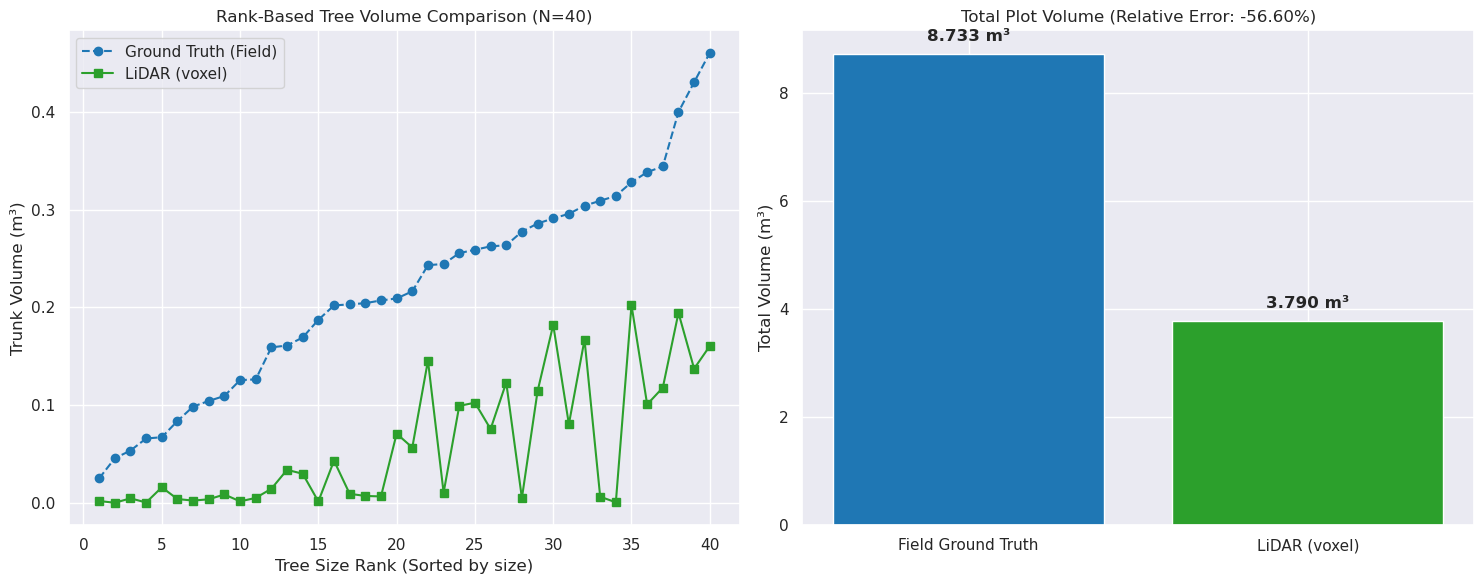

In [35]:
# Extract data for the overall best parameter set
best_overall = df_summary.iloc[0]
print(f"Plotting results for best overall model: {best_overall['volume_method']} with parameters: {best_overall['volume_params']}")

valid_tasks = df_res[
    (df_res["dbh_method"] == best_overall["dbh_method"]) &
    (df_res["dbh_params_str"] == best_overall["dbh_params"]) &
    (df_res["volume_method"] == best_overall["volume_method"]) & 
    (df_res["volume_params_str"] == best_overall["volume_params"]) &
    (df_res["status"] == "success")
].sort_values("height_m")

est_vols = valid_tasks["volume_m3"].values
n_match = min(len(est_vols), len(gt_volumes_sorted))

plt.figure(figsize=(15, 6))

# Subplot 1: Matched tree volumes
plt.subplot(1, 2, 1)
plt.plot(range(1, n_match + 1), gt_volumes_sorted[:n_match], 'o--', color='#1f77b4', label='Ground Truth (Field)')
plt.plot(range(1, n_match + 1), est_vols[:n_match], 's-', color='#2ca02c', label=f'LiDAR ({best_overall["volume_method"]})')
plt.xlabel('Tree Size Rank (Sorted by size)')
plt.ylabel('Trunk Volume (m³)')
plt.title(f'Rank-Based Tree Volume Comparison (N={n_match})')
plt.legend()

# Subplot 2: Total plot volume
plt.subplot(1, 2, 2)
bars = plt.bar(['Field Ground Truth', f'LiDAR ({best_overall["volume_method"]})'], [gt_total_volume, best_overall['est_total_volume_m3']], color=['#1f77b4', '#2ca02c'])
plt.ylabel('Total Volume (m³)')
plt.title(f'Total Plot Volume (Relative Error: {best_overall["plot_volume_rel_err_pct"]:.2f}%)')
for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2.0, yval + 0.02 * gt_total_volume, f"{yval:.3f} m³", ha='center', va='bottom', fontweight='bold')

plt.tight_layout()
plt.show()


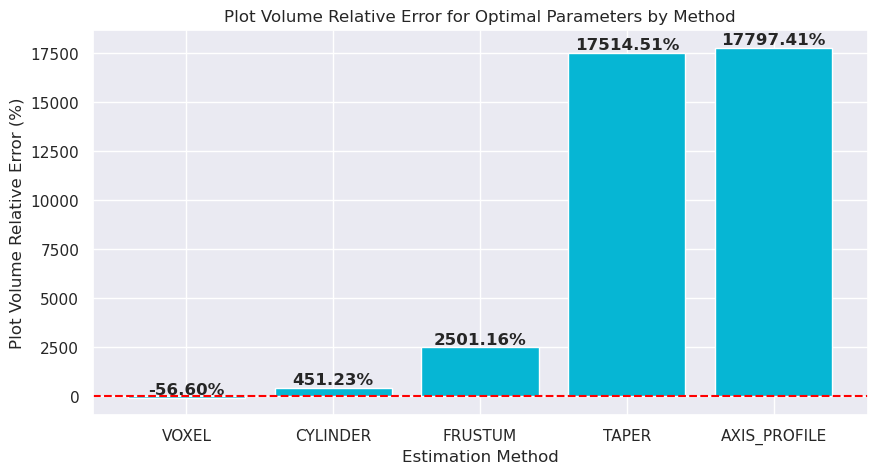

In [36]:
# Relative Plot Errors across all best-performing methods
plt.figure(figsize=(10, 5))

best_by_method = []
for m in df_summary["volume_method"].unique():
    best_by_method.append(df_summary[df_summary["volume_method"] == m].iloc[0])

df_best_by_method = pd.DataFrame(best_by_method)
bars = plt.bar(df_best_by_method["volume_method"].str.upper(), df_best_by_method["plot_volume_rel_err_pct"], color='#06b6d4')
plt.axhline(0, color='red', linestyle='--')
plt.ylabel('Plot Volume Relative Error (%)')
plt.xlabel('Estimation Method')
plt.title('Plot Volume Relative Error for Optimal Parameters by Method')

for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2.0, yval + (2 if yval >= 0 else -4), f"{yval:.2f}%", ha='center', va='bottom', fontweight='bold')

plt.show()
